In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Download a sample sales dataset (for example, from Kaggle or use a small CSV you create) with columns like product, category, date, and sales amount. Load it into a Pandas DataFrame and display the first 5 rows to verify the data.

In [2]:
# Create a sample sales dataset
data = {
    'Product': ['Laptop', 'Mobile', 'Headphones', 'Keyboard', 'Mouse',
                'Monitor', 'Tablet', 'Laptop', 'Mouse', 'Mobile'],
    'Category': ['Electronics', 'Electronics', 'Accessories', 'Accessories',
                 'Accessories', 'Electronics', 'Electronics', 'Electronics',
                 'Accessories', 'Electronics'],
    'Date': ['2026-01-05', '2026-01-06', '2026-01-07', '2026-01-08',
             '2026-01-09', '2026-01-10', '2026-01-11', '2026-01-12',
             '2026-01-13', '2026-01-14'],
    'Sales_Amount': [55000, 25000, 1500, 2000, 800,
                     18000, 22000, 55000, 800, 25000]
}

# Convert the data into a DataFrame
df = pd.DataFrame(data)

# Save the dataset as a CSV file
df.to_csv('sales_dataset.csv', index=False)

# Load the CSV file into Pandas
df = pd.read_csv('sales_dataset.csv')

# Display the first 5 rows
print(df.head())

      Product     Category        Date  Sales_Amount
0      Laptop  Electronics  2026-01-05         55000
1      Mobile  Electronics  2026-01-06         25000
2  Headphones  Accessories  2026-01-07          1500
3    Keyboard  Accessories  2026-01-08          2000
4       Mouse  Accessories  2026-01-09           800


Using Matplotlib, create a bar chart that shows total sales for each product category (like 'Electronics', 'Clothing', 'Groceries'), similar to how Flipkart or Myntra might track category performance.

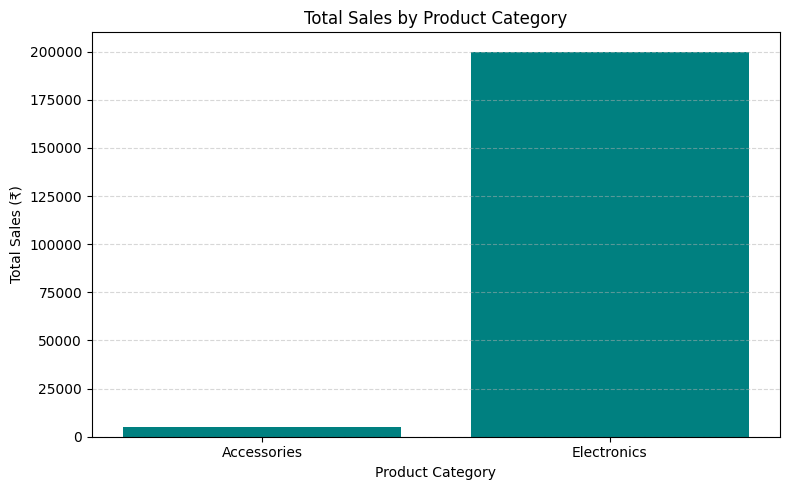

In [7]:
df = pd.DataFrame(data)

# Calculate total sales for each category
category_sales = df.groupby('Category')['Sales_Amount'].sum()

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(category_sales.index, category_sales.values, color='teal')

# Add title and axis labels
plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales (₹)')

# Add gridlines
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Plot a line chart to visualize monthly sales trends over a year, using the date column to group sales by month. Add a title and axis labels to make the chart presentation-ready.

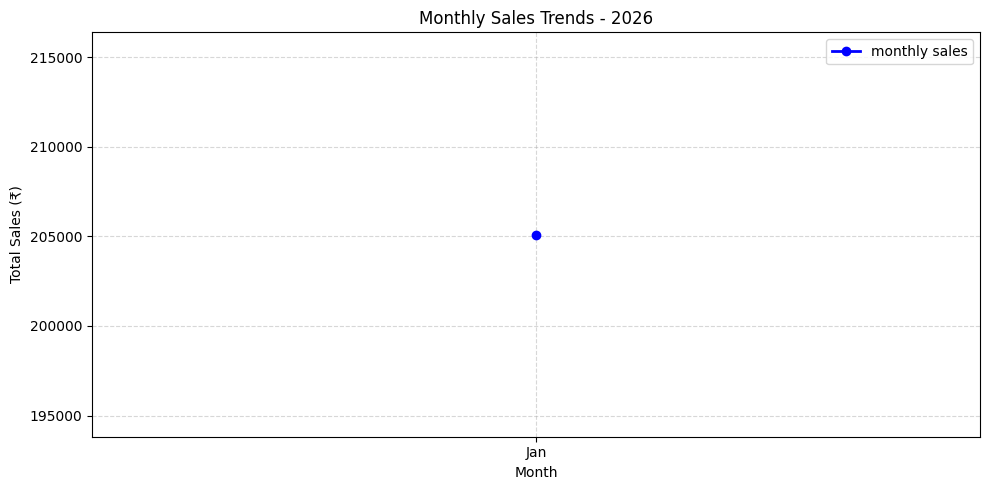

In [14]:
df = pd.DataFrame(data)

# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Group sales by month
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Sales_Amount'].sum()

# Convert monthly periods to timestamps for plotting
monthly_sales.index = monthly_sales.index.to_timestamp()

# Create line chart
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values,
         marker='o', color='blue', linewidth=2, label='monthly sales')

# Add title and axis labels
plt.title('Monthly Sales Trends - 2026')
plt.xlabel('Month')
plt.ylabel('Total Sales (₹)')

# Improve presentation
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(monthly_sales.index, monthly_sales.index.strftime('%b'))
plt.legend()
plt.tight_layout()
plt.show()

Create a histogram to show the distribution of order amounts (sales values), highlighting how many small vs. large purchases happen — like analyzing order size patterns on Zomato or Swiggy.<br><br><em><strong>Hint:</strong> Use plt.hist() and set bins to 10 for a clear distribution.</em>

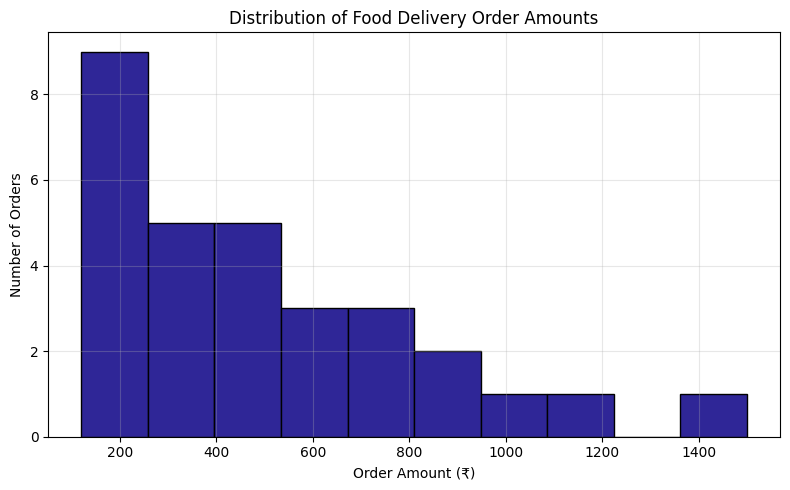

In [18]:
order_amounts = [
    120, 250, 180, 350, 450, 220, 150, 500, 700, 300,
    280, 400, 550, 650, 800, 900, 350, 200, 150, 1200,
    750, 600, 450, 300, 180, 1000, 850, 400, 250, 1500
]

# Create histogram
plt.figure(figsize=(8, 5))
plt.hist(order_amounts, bins=10, color="#2F2697", edgecolor='black')

# Add title and labels
plt.title('Distribution of Food Delivery Order Amounts')
plt.xlabel('Order Amount (₹)')
plt.ylabel('Number of Orders')

# Add gridlines
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Add value annotations to your category bar chart to display the exact sales amount above each bar, then export the chart as a PNG image file named 'category_sales_kpi.png'.

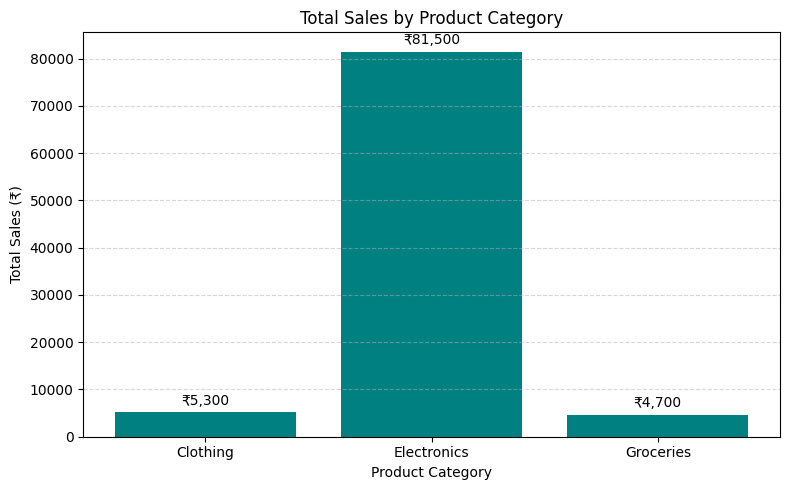

In [16]:
data = {
    'Category': [
        'Electronics', 'Clothing', 'Groceries',
        'Electronics', 'Clothing', 'Groceries',
        'Electronics', 'Clothing', 'Groceries'
    ],
    'Sales_Amount': [
        55000, 2500, 1200,
        25000, 1800, 1500,
        1500, 1000, 2000
    ]
}

df = pd.DataFrame(data)

# Calculate total sales per category
category_sales = df.groupby('Category')['Sales_Amount'].sum()

# Create bar chart
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    category_sales.index,
    category_sales.values,
    color='teal'
)

# Add exact values above each bar
ax.bar_label(
    bars,
    labels=[f'₹{value:,.0f}' for value in category_sales.values],
    padding=3
)

# Add title and labels
ax.set_title('Total Sales by Product Category')
ax.set_xlabel('Product Category')
ax.set_ylabel('Total Sales (₹)')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

# Export as PNG
plt.savefig(
    'category_sales_kpi.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()